<div dir="rtl">

# تحلیل توصیفی دیدگاه‌های دیجی‌کالا

این نوت‌بوک بخش A تعریف پروژه را پیاده‌سازی می‌کند. فایل CSV با پردازش تکه‌ای خوانده می‌شود تا کل داده هم‌زمان وارد حافظه نشود. شمارش‌ها و آمارهای کلی از کل داده محاسبه می‌شوند؛ نمونه محدود فقط در تحلیل واژگانی اختیاری استفاده می‌شود.

## آماده‌سازی

مسیر فایل داده و ابزارهای لازم را مشخص می‌کنیم. فایل منبع فقط خوانده می‌شود.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import json
from IPython.display import display
import numpy as np

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "src":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw_data" / "digikala-comments.csv"
REPORT_DIR = PROJECT_ROOT / "reports" / "preprocess"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# توابع کمکی، فایل را تکه‌ای می‌خوانند و برای ممیزی دقیق از SQLite استفاده می‌کنند.
from eda_audit import scan_csv, histogram_summary, cross_table, duplicate_audit
if not DATA_PATH.exists():
    raise FileNotFoundError(f"فایل داده پیدا نشد: {DATA_PATH}")
CHUNK_SIZE = 100_000
SAMPLE_SIZE = 20_000
SEED = 2026
LABEL_MISSING_TOKENS = {"nan"}  # این مقدار لفظی در ستون برچسب به‌عنوان مقدار گمشده دیده شد.
print(f"فایل داده: {DATA_PATH}")
print(f"اندازه فایل: {DATA_PATH.stat().st_size / (1024 ** 3):.2f} گیگابایت")

فایل داده: E:\MLprojects\Transformer-Project\data\raw_data\digikala-comments.csv
اندازه فایل: 1.19 گیگابایت


<div dir="rtl">

## A1. اندازه و ساختار داده

تعداد واقعی ردیف‌ها با CSV parser شمرده می‌شود. تعداد ستون‌ها، نوع داده‌ها، اندازه فایل، تعداد محصولات و فروشندگان یکتا و توزیع دیدگاه‌ها به‌ازای محصول نیز گزارش می‌شوند.

In [2]:
results = scan_csv(DATA_PATH, chunksize=CHUNK_SIZE, sample_size=SAMPLE_SIZE, seed=SEED, progress=True)
schema = pd.read_csv(DATA_PATH, nrows=100_000).dtypes.astype(str).rename("نوع داده (استنباط‌شده از ۱۰۰هزار ردیف اول)").to_frame()
print(f"تعداد رکوردها: {results['rows']:,}")
print(f"تعداد ستون‌ها: {len(results['columns'])}")
print(f"تعداد محصولات یکتا: {len(results['counts']['products']):,}")
print(f"تعداد فروشندگان یکتا: {len(results['counts']['sellers']):,}")
display(schema)
product_review_counts = pd.Series(results['counts']['products'], dtype='int64')
product_frequency = product_review_counts.value_counts().sort_index().rename_axis("تعداد دیدگاه برای هر محصول").rename("تعداد محصولات").to_frame()
display(product_frequency.head(30))
product_frequency.to_csv(REPORT_DIR / "a1_product_review_frequency.csv", encoding="utf-8-sig")

100,000 rows scanned | 3.2s
1,000,000 rows scanned | 24.5s
2,000,000 rows scanned | 48.5s
3,000,000 rows scanned | 72.2s
4,000,000 rows scanned | 95.9s
5,000,000 rows scanned | 118.7s
6,000,000 rows scanned | 141.4s
تعداد رکوردها: 6,156,289
تعداد ستون‌ها: 15
تعداد محصولات یکتا: 331,599
تعداد فروشندگان یکتا: 29,214


,نوع داده (استنباط‌شده از ۱۰۰هزار ردیف اول)
id,int64
title,str
body,str
created_at,str
rate,float64
recommendation_status,str
is_buyer,bool
product_id,int64
advantages,str
disadvantages,str


,تعداد محصولات
تعداد دیدگاه برای هر محصول,
1,91944
2,45109
3,27595
4,19212
5,14598
6,11521
7,9315
8,7661
9,6570


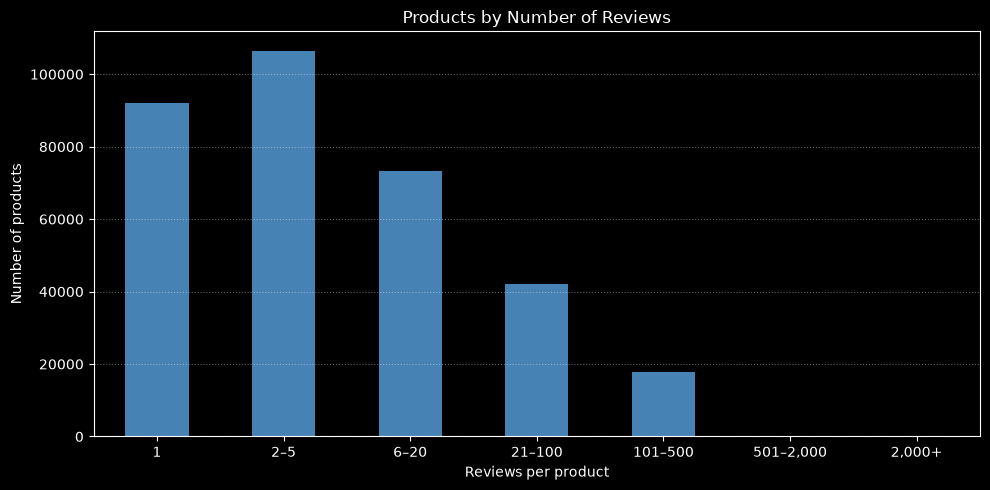

,Number of products
1,91944
2–5,106514
6–20,73204
21–100,42033
101–500,17904
"501–2,000",0
"2,000+",0


In [3]:
# توزیع تعداد دیدگاه‌ها بین محصولات در بازه‌های مختلف
review_counts = product_review_counts.to_numpy()

bins = [0, 1, 5, 20, 100, 500, 2_000, float("inf")]
labels = ["1", "2–5", "6–20", "21–100", "101–500", "501–2,000", "2,000+"]

review_groups = pd.cut(
    review_counts,
    bins=bins,
    labels=labels,
    include_lowest=True
)

# تبدیل به Series برای سازگاری با نسخه‌های مختلف Pandas
product_distribution = (
    pd.Series(review_groups)
    .value_counts(sort=False)
    .reindex(labels, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 5))
product_distribution.plot(kind="bar", ax=ax, color="steelblue")

ax.set_title("Products by Number of Reviews")
ax.set_xlabel("Reviews per product")
ax.set_ylabel("Number of products")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

display(product_distribution.rename("Number of products").to_frame())


In [4]:
file_size_bytes = DATA_PATH.stat().st_size
print(f"\u0627\u0646\u062f\u0627\u0632\u0647 \u0641\u0627\u06cc\u0644 \u062f\u0627\u062f\u0647: {file_size_bytes:,} bytes ({file_size_bytes / 1_000_000_000:.2f} GB)")


اندازه فایل داده: 1,278,526,959 bytes (1.28 GB)


<div dir="rtl">

## A2. الگوهای مقادیر گمشده

برای هر ستون تعداد و درصد مقادیر گمشده را نشان می‌دهیم. سپس رابطه گم‌شدن برچسب توصیه را با وضعیت خریدار و مقدار rate بررسی می‌کنیم. خانه‌های خالی و رشته‌های فقط شامل فاصله نیز جداگانه شمرده می‌شوند.

برچسب توصیه در برابر is_buyer:


,<MISSING>,no_idea,not_recommended,recommended
False,302181,0,0,0
True,592245,594121,504903,4162839


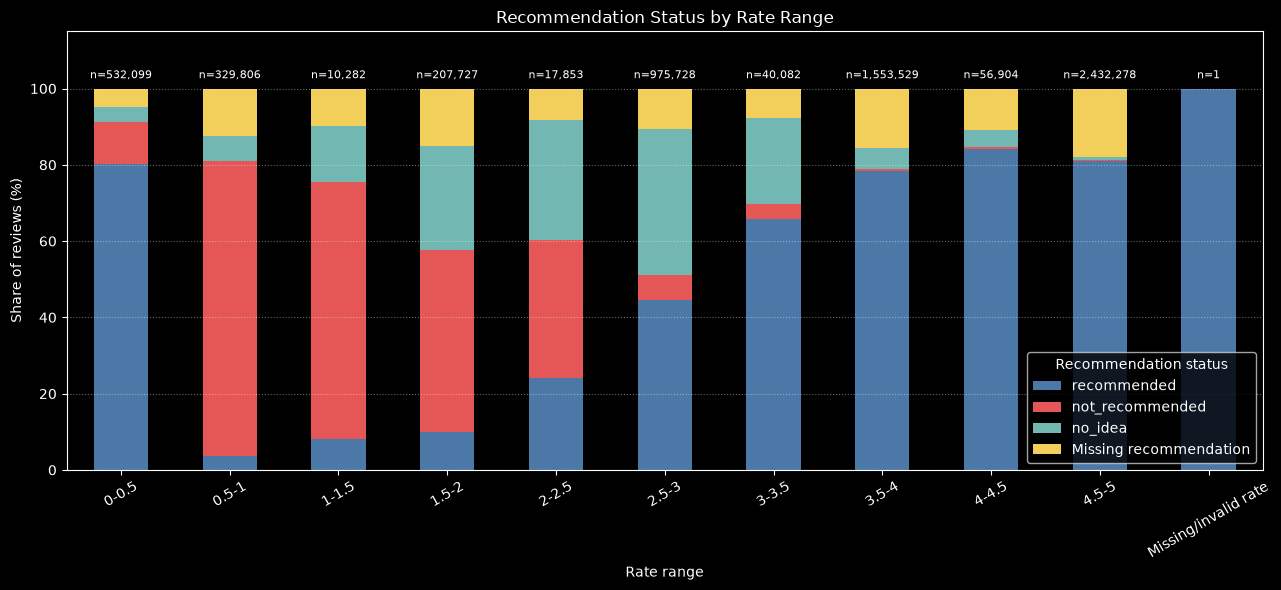

مقادیر خالی یا فقط فاصله:


,تعداد
title,1353
id,0
body,0
created_at,0
rate,0
recommendation_status,0
is_buyer,0
product_id,0
advantages,0
disadvantages,0


,تعداد گمشده,درصد گمشده
recommendation_status,894426,14.529
body,637,0.010
id,0,0.000
title,0,0.000
created_at,0,0.000
rate,0,0.000
is_buyer,0,0.000
product_id,0,0.000
advantages,0,0.000
disadvantages,0,0.000


,count
body value category,
empty_field,0
whitespace_only,0
text_token:n/a,0
text_token:na,0
text_token:nan,637
text_token:none,0
text_token:null,0


,has_label,missing_label,درصد برچسب گمشده
product_id,,,
1,73275,18669,20.30
2 تا 5,261579,61262,18.98
6 تا 20,652870,135662,17.20
بیش از 20,4274139,678833,13.71


In [5]:
missing = pd.Series(results['counts']['missing'], dtype='int64').reindex(results['columns'], fill_value=0)
print("برچسب توصیه در برابر is_buyer:")
display(cross_table(results['cross'].get('is_buyer_label', {})))
# ارتباط وضعیت توصیه با بازه‌های rate؛ شامل برچسب و rate گمشده/نامعتبر
rate_label_counts = cross_table(
    results["cross"].get("rate_label", {})
)

recommendation_classes = [
    "recommended",
    "not_recommended",
    "no_idea",
    "<MISSING>",
]

rate_counts = rate_label_counts.reindex(
    columns=recommendation_classes,
    fill_value=0
).astype("int64")

# rateهای عددی معتبر را به بازه‌های نیم‌امتیازی گروه‌بندی می‌کنیم
numeric_rates = pd.to_numeric(rate_counts.index, errors="coerce")
valid_rate_mask = (
    pd.notna(numeric_rates)
    & (numeric_rates >= 0)
    & (numeric_rates <= 5)
)

valid_counts = rate_counts.loc[valid_rate_mask].copy()
valid_counts.index = numeric_rates[valid_rate_mask]

rate_bins = np.arange(0, 5.5, 0.5)
rate_bin_labels = [
    f"{left:g}-{right:g}"
    for left, right in zip(rate_bins[:-1], rate_bins[1:])
]

rate_groups = pd.cut(
    valid_counts.index,
    bins=rate_bins,
    labels=rate_bin_labels,
    include_lowest=True
)

binned_counts = valid_counts.groupby(rate_groups, observed=False).sum()
binned_counts = binned_counts.reindex(rate_bin_labels, fill_value=0)

# یک ستون جدا برای rate خالی یا نامعتبر
invalid_rate_counts = rate_counts.loc[~valid_rate_mask].sum(axis=0)
binned_counts.loc["Missing/invalid rate"] = invalid_rate_counts

# محاسبه سهم هر وضعیت توصیه در هر بازه rate
sample_counts = binned_counts.sum(axis=1)
binned_percent = (
    binned_counts
    .div(sample_counts.replace(0, pd.NA), axis=0)
    .fillna(0)
    * 100
)

binned_percent = binned_percent.rename(
    columns={"<MISSING>": "Missing recommendation"}
)

fig, ax = plt.subplots(figsize=(13, 6))
binned_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#E45756", "#72B7B2", "#F2CF5B"]
)

ax.set_title("Recommendation Status by Rate Range")
ax.set_xlabel("Rate range")
ax.set_ylabel("Share of reviews (%)")
ax.set_ylim(0, 115)
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.legend(title="Recommendation status")

for position, count in enumerate(sample_counts):
    ax.text(position, 102, f"n={count:,}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

print("مقادیر خالی یا فقط فاصله:")
display(pd.Series(results['counts']['blank'], name="تعداد").sort_values(ascending=False).to_frame())
# ارتباط گم‌شدن برچسب با تعداد دیدگاه‌های محصول، در یک گذر دوم
BODY_MISSING_TOKEN_CANDIDATES = {"nan", "none", "null", "n/a", "na"}
body_token_counts = {token: 0 for token in BODY_MISSING_TOKEN_CANDIDATES}
body_empty_count = 0
body_whitespace_count = 0
product_frequency_band = product_review_counts.map(
    lambda count: "1" if count == 1 else "2 تا 5" if count <= 5 else "6 تا 20" if count <= 20 else "بیش از 20"
)
missing_label_by_product_frequency = {}
for chunk in pd.read_csv(
    DATA_PATH, usecols=["product_id", "recommendation_status", "body"], dtype="string",
    keep_default_na=False, na_values=[""], chunksize=CHUNK_SIZE, on_bad_lines="error"
):
    body = chunk["body"]
    stripped_body = body.fillna("").str.strip()
    body_empty_count += int(body.isna().sum())
    body_whitespace_count += int((body.notna() & stripped_body.eq("")).sum())
    normalized_body = stripped_body.str.lower()
    for token in BODY_MISSING_TOKEN_CANDIDATES:
        body_token_counts[token] += int(normalized_body.eq(token).sum())

    product_band = chunk["product_id"].map(product_frequency_band).fillna("شناسه محصول ناموجود")
    label_missing = chunk["recommendation_status"].isna() | chunk["recommendation_status"].astype("string").str.strip().str.lower().isin(LABEL_MISSING_TOKENS)
    part = pd.crosstab(product_band, label_missing).reindex(columns=[False, True], fill_value=0)
    missing_label_by_product_frequency["has_label"] = (
        missing_label_by_product_frequency.get("has_label", pd.Series(dtype="int64")).add(part[False], fill_value=0)
    )
    missing_label_by_product_frequency["missing_label"] = (
        missing_label_by_product_frequency.get("missing_label", pd.Series(dtype="int64")).add(part[True], fill_value=0)
    )
# Count text sentinels like pandas read_csv default, while reporting their types separately.
missing.loc["body"] += sum(body_token_counts.values())
missing_table = pd.DataFrame({"تعداد گمشده": missing, "درصد گمشده": (100 * missing / results['rows']).round(3)})
display(missing_table.sort_values("تعداد گمشده", ascending=False))
body_missing_audit_table = pd.DataFrame.from_dict(
    {"empty_field": body_empty_count, "whitespace_only": body_whitespace_count,
     **{f"text_token:{token}": count for token, count in sorted(body_token_counts.items())}},
    orient="index", columns=["count"]
)
body_missing_audit_table.index.name = "body value category"
display(body_missing_audit_table)
missing_table.to_csv(REPORT_DIR / "a2_missing_values.csv", encoding="utf-8-sig")
body_missing_audit_table.to_csv(REPORT_DIR / "a2_body_missing_audit.csv", encoding="utf-8-sig")

product_label_table = pd.DataFrame(missing_label_by_product_frequency).fillna(0).astype("int64")
product_label_table["درصد برچسب گمشده"] = (
    100 * product_label_table["missing_label"] /
    (product_label_table["has_label"] + product_label_table["missing_label"]).replace(0, pd.NA)
).round(2)
display(product_label_table)


<div dir="rtl">

## A3. توزیع هدف‌ها و آمار rate

مقادیر واقعی برچسب توصیه را بدون فرض درباره واژگان آن‌ها گزارش می‌کنیم. سپس rating_band را با آستانه‌های ثابت پروژه می‌سازیم. rate خام فقط برای ساخت هدف به کار می‌رود و نباید ویژگی ورودی مدل باشد.

,تعداد,درصد از برچسب‌های موجود
recommended,4162839,79.113
no_idea,594121,11.291
not_recommended,504903,9.596


,تعداد,درصد از نرخ‌های معتبر
low,1092329,17.743
medium,1059054,17.203
high,4004905,65.054
invalid,1,NaN


آستانه‌ها: low: 0 ≤ rate < 2.5، medium: 2.5 ≤ rate < 4، high: 4 ≤ rate ≤ 5


,آمار rate
count,6.156289e+06
min,0.000000e+00
mean,3.648286e+00
std,1.861854e+00
max,2.500000e+03
p25,3.000000e+00
p50,4.000000e+00
p75,5.000000e+00
p90,5.000000e+00
p95,5.000000e+00


تعداد rate یکتای قابل‌تجزیه: 178
سهم مقادیر اعشاری در rateهای معتبر: 3.71%


,تعداد داده نامعتبر/کیفی
rate_missing,0
rate_non_numeric,0
rate_nonfinite,0
rate_out_of_range,1
rate_zero,529098
rate_fractional_valid,228128
body_missing,0
unknown_label,0
missing_product,0
missing_id,0


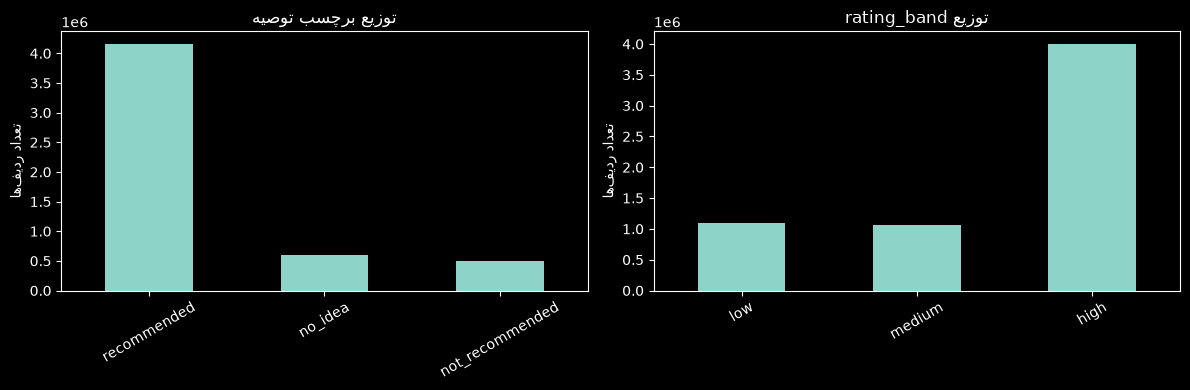

نام برچسب‌های خام را بررسی و نگاشت قطعی آن‌ها به کلاس‌های معیار را مستند کنید.


In [6]:
label_counts = pd.Series(results['counts']['raw_labels'], dtype='int64').drop(index=list(LABEL_MISSING_TOKENS), errors="ignore").sort_values(ascending=False)
label_table = pd.DataFrame({"تعداد": label_counts, "درصد از برچسب‌های موجود": (100 * label_counts / max(label_counts.sum(), 1)).round(3)})
display(label_table)
band_counts = pd.Series(results['counts']['bands'], dtype='int64').reindex(["low", "medium", "high", "invalid"], fill_value=0)
valid_band_total = int(band_counts[["low", "medium", "high"]].sum())
band_percent = (100 * band_counts / max(valid_band_total, 1)).round(3)
band_percent.loc["invalid"] = pd.NA
band_table = pd.DataFrame({"تعداد": band_counts, "درصد از نرخ‌های معتبر": band_percent})
display(band_table)
print("آستانه‌ها: low: 0 ≤ rate < 2.5، medium: 2.5 ≤ rate < 4، high: 4 ≤ rate ≤ 5")
display(histogram_summary(results['counts']['rates']).to_frame("آمار rate"))
valid_rate_count = sum(results['counts']['rates'].values()) - results['counts']['quality']['rate_out_of_range']
fractional_count = results['counts']['quality']['rate_fractional_valid']
print(f"تعداد rate یکتای قابل‌تجزیه: {len(results['counts']['rates']):,}")
print(f"سهم مقادیر اعشاری در rateهای معتبر: {fractional_count / max(valid_rate_count, 1):.2%}")
display(pd.Series(results['counts']['quality'], name="تعداد داده نامعتبر/کیفی").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
label_counts.plot(kind="bar", ax=axes[0], title="توزیع برچسب توصیه")
band_counts.drop("invalid").plot(kind="bar", ax=axes[1], title="توزیع rating_band")
for ax in axes:
    ax.set_ylabel("تعداد ردیف‌ها")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("نام برچسب‌های خام را بررسی و نگاشت قطعی آن‌ها به کلاس‌های معیار را مستند کنید.")

<div dir="rtl">

## A4. تحلیل طول متن

طول نویسه‌ای و تعداد واژه‌های body را از کل ردیف‌های دارای متن گزارش می‌کنیم. خلاصه کلی و خلاصه به تفکیک برچسب به انتخاب max_length و سیاست کوتاه‌سازی کمک می‌کند.

,برچسب,معیار طول,count,min,mean,std,max,p25,p50,p75,p90,p95,p99,p99.9
0,not_recommended,characters,504903.0,1.0,73.258155,80.647821,3148.0,25.0,48.0,92.0,159.0,217.0,383.0,745.098
1,not_recommended,words,504903.0,1.0,15.164261,16.723421,623.0,5.0,10.0,19.0,33.0,45.0,79.0,154.000
2,recommended,characters,4162839.0,1.0,44.248011,58.196263,4000.0,15.0,27.0,52.0,95.0,136.0,267.0,601.000
3,recommended,words,4162839.0,1.0,9.231886,12.101003,908.0,3.0,6.0,11.0,20.0,28.0,56.0,125.000
4,<MISSING>,characters,894426.0,1.0,46.409027,71.763889,4000.0,12.0,25.0,54.0,105.0,155.0,321.0,758.000
5,<MISSING>,words,894426.0,1.0,9.685076,14.863305,853.0,2.0,5.0,11.0,22.0,32.0,67.0,158.000
6,no_idea,characters,594121.0,1.0,59.298143,71.591385,3336.0,19.0,38.0,73.0,129.0,181.0,336.0,702.000
7,no_idea,words,594121.0,1.0,12.360257,14.909157,696.0,4.0,8.0,15.0,27.0,38.0,70.0,146.000


تعداد دیدگاه‌های بسیار کوتاه (۱ یا ۲ واژه): 1023154
تعداد دیدگاه‌های بسیار بلند (بیش از ۵۰۰ واژه): 82
خلاصه طول characters:


,مقدار
count,6.156289e+06
min,1.000000e+00
mean,4.839365e+01
std,6.434898e+01
max,4.000000e+03
p25,1.500000e+01
p50,2.900000e+01
p75,5.700000e+01
p90,1.060000e+02
p95,1.520000e+02


خلاصه طول words:


,مقدار
count,6.156289e+06
min,1.000000e+00
mean,1.008617e+01
std,1.336540e+01
max,9.080000e+02
p25,3.000000e+00
p50,6.000000e+00
p75,1.200000e+01
p90,2.200000e+01
p95,3.200000e+01


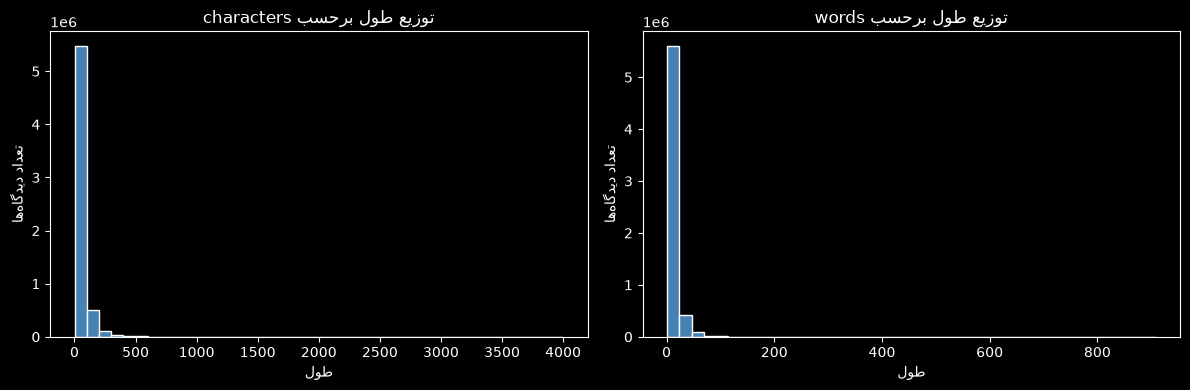

In [7]:
length_rows = []
for label, metrics in results['by_label'].items():
    for metric, frequency in metrics.items():
        if metric in ("characters", "words"):
            length_rows.append({"برچسب": label, "معیار طول": metric, **histogram_summary(frequency).to_dict()})
length_by_label = pd.DataFrame(length_rows)
display(length_by_label)
print("تعداد دیدگاه‌های بسیار کوتاه (۱ یا ۲ واژه):", results['counts']['signals']['very_short_1_2_words'])
print("تعداد دیدگاه‌های بسیار بلند (بیش از ۵۰۰ واژه):", results['counts']['signals']['long_over_500_words'])
for metric, frequency in results['lengths'].items():
    print(f"خلاصه طول {metric}:")
    display(histogram_summary(frequency).to_frame("مقدار"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(["characters", "words"], axes):
    values = pd.Series(results['lengths'][metric])
    ax.hist(values.index, weights=values.values, bins=40, color="steelblue", edgecolor="white")
    ax.set_title(f"توزیع طول برحسب {metric}")
    ax.set_xlabel("طول")
    ax.set_ylabel("تعداد دیدگاه‌ها")
plt.tight_layout()
plt.show()

## A5. تکرار، برچسب‌های متناقض و تمرکز محصول

تعداد دیدگاه‌ها برای هر محصول از اسکن کامل به دست آمده است. ممیزی شناسه و متن تکراری و متن یکسان با هدف متناقض با SQLite انجام می‌شود تا همه متن‌ها هم‌زمان در حافظه بارگذاری نشوند. این مرحله ممکن است زمان‌بر و نیازمند فضای دیسک باشد.

In [8]:
import importlib
import eda_audit
importlib.reload(eda_audit)
duplicate_audit = eda_audit.duplicate_audit
duplicate_db = REPORT_DIR / "a5_duplicate_audit.sqlite"
duplicate_results = duplicate_audit(DATA_PATH, db_path=duplicate_db, chunksize=CHUNK_SIZE, progress=True)
display(duplicate_results['summary'])
print("\u0646\u0645\u0648\u0646\u0647 \u0645\u062a\u0646\u200c\u0647\u0627\u06cc \u062a\u06a9\u0631\u0627\u0631\u06cc:")
display(duplicate_results['repeated'].head(20))
print("\u0646\u0645\u0648\u0646\u0647 \u0645\u062a\u0646\u200c\u0647\u0627\u06cc \u062f\u0627\u0631\u0627\u06cc \u0647\u062f\u0641 \u0645\u062a\u0646\u0627\u0642\u0636:")
display(duplicate_results['conflicts'].head(20))
display(product_review_counts.describe(percentiles=[.5, .9, .95, .99]).to_frame("\u062a\u0639\u062f\u0627\u062f \u062f\u06cc\u062f\u06af\u0627\u0647 \u0628\u0631\u0627\u06cc \u0647\u0631 \u0645\u062d\u0635\u0648\u0644"))


,duplicate_id_groups,excess_id_rows,duplicate_body_groups,excess_body_rows,recommendation_conflict_groups,rating_band_conflict_groups
0,3226,3229,197745,2020031,31942,82620


نمونه متن‌های تکراری:


,body,n,labels,bands
0,عالی,121349,3,3
1,خوب بود,73854,3,3
2,خوبه,72210,3,3
3,خوب,64297,3,3
4,عالی بود,23598,3,3
5,عالیه,19719,3,3
6,معمولی,13185,3,3
7,خیلی خوب بود,13130,3,3
8,خوب بود,12014,3,3
9,پیشنهاد میکنم,11165,3,3


نمونه متن‌های دارای هدف متناقض:


,body,n,labels,bands
0,عالی,121349,3,3
1,خوب بود,73854,3,3
2,خوبه,72210,3,3
3,خوب,64297,3,3
4,عالی بود,23598,3,3
5,عالیه,19719,3,3
6,معمولی,13185,3,3
7,خیلی خوب بود,13130,3,3
8,خوب بود,12014,3,3
9,پیشنهاد میکنم,11165,3,3


,تعداد دیدگاه برای هر محصول
count,331599.000000
mean,18.565463
std,40.934097
min,1.000000
50%,4.000000
90%,46.000000
95%,110.000000
99%,200.000000
max,400.000000


## A6. تحلیل واژگانی (اختیاری)

این بخش اختیاری است و واژه‌های پرتکرار را در نمونه تصادفی محدود نشان می‌دهد. حذف واژه‌های توقف انجام نمی‌شود و باید جداگانه به‌عنوان آزمایش ارزیابی شود.

In [9]:
from collections import Counter
import re
print(f"اندازه نمونه: {len(results['sample']):,} ردیف؛ seed={SEED}")
print("قاعده نمونه‌گیری: اولویت‌های تصادفی یکنواخت با نگه‌داشتن کمترین اولویت‌ها در اسکن تکه‌ای.")
word_counts = Counter()
for text in results['sample']["body"].dropna().astype(str):
    word_counts.update(re.findall(r"[^\W_]+", text.lower(), flags=re.UNICODE))
display(pd.DataFrame(word_counts.most_common(30), columns=["واژه", "تعداد"]))

اندازه نمونه: 20,000 ردیف؛ seed=2026
قاعده نمونه‌گیری: اولویت‌های تصادفی یکنواخت با نگه‌داشتن کمترین اولویت‌ها در اسکن تکه‌ای.


,واژه,تعداد
0,و,8979
1,بود,4637
2,خیلی,4395
3,خوب,3625
4,به,3554
5,از,3272
6,خوبه,3075
7,که,2823
8,عالی,2622
9,من,2512


## A7. خروجی تحلیل توصیفی

نوت‌بوک جدول‌ها، نمودارها و خلاصه‌های موردنیاز را تولید می‌کند. نتایج جدولی در reports/preprocess ذخیره می‌شوند. برای گزارش نهایی، دست‌کم پنج نتیجه‌گیری مستدل را از خروجی واقعی بنویسید و روشن کنید هر نمودار از کل داده استفاده کرده یا از نمونه. یافته‌ها را به روش تقسیم بر اساس محصول، وزن‌دهی کلاس‌ها، طول دنباله، نرمال‌سازی و معیارهای ارزیابی پیوند دهید.

In [10]:
missing_table.to_csv(REPORT_DIR / "a2_missing_values.csv", encoding="utf-8-sig")
body_missing_audit_table.to_csv(REPORT_DIR / "a2_body_missing_audit.csv", encoding="utf-8-sig")
label_table.to_csv(REPORT_DIR / "a3_recommendation_distribution.csv", encoding="utf-8-sig")
band_table.to_csv(REPORT_DIR / "a3_rating_band_distribution.csv", encoding="utf-8-sig")
length_by_label.to_csv(REPORT_DIR / "a4_text_length_by_label.csv", index=False, encoding="utf-8-sig")
print(f"جدول‌های خروجی در این مسیر ذخیره شدند: {REPORT_DIR}")

جدول‌های خروجی در این مسیر ذخیره شدند: E:\MLprojects\Transformer-Project\reports\preprocess


---
# بخش B — پاک‌سازی، تقسیم داده و پروتکل برچسب

در این بخش متن فارسی نرمال‌سازی می‌شود، تقسیم مشترک و قطعی بر اساس محصول ساخته می‌شود و بخشی از برچسب‌های آموزشی طبق پروتکل پروژه کنار گذاشته می‌شوند. فایل اصلی تغییر نمی‌کند.

## B1. نرمال‌سازی متن فارسی

«ي» و «ك» عربی به شکل فارسی تبدیل می‌شوند، entityهای HTML باز و تگ‌ها حذف می‌شوند، URLها با نشانگر <URL> جایگزین می‌شوند و فاصله‌ها سامان‌دهی می‌شوند. نیم‌فاصله فارسی، اعداد، ایموجی‌ها و واژه‌های نفی حفظ می‌شوند؛ نویسه‌های نامرئی فاصله‌ساز و علامت‌های جهت متن حذف می‌شوند.

In [11]:
import html
import re
import unicodedata

ARABIC_TO_PERSIAN = str.maketrans({"ي": "ی", "ك": "ک"})
URL_PATTERN = re.compile(r"(?i)(?:https?://|www\.)\S+")
HTML_TAG_PATTERN = re.compile(r"<[^>]+>")
INVISIBLE_PATTERN = re.compile(r"[\u200b\ufeff\u200e\u200f\u202a-\u202e\u2066-\u2069]")

def normalize_persian_text(value):
    """متن را نرمال می‌کند؛ عدد، ایموجی، نیم‌فاصله و نفی را نگه می‌دارد."""
    if pd.isna(value):
        return pd.NA
    text = html.unescape(str(value)).translate(ARABIC_TO_PERSIAN)
    text = HTML_TAG_PATTERN.sub(" ", text)
    text = URL_PATTERN.sub(" <URL> ", text)
    text = INVISIBLE_PATTERN.sub("", text)
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", text)).strip()

print(normalize_persian_text("کیفیت عالی بود 🙂، پیشنهاد می‌کنم. عدد ۱۲۳ و https://example.com"))

کیفیت عالی بود 🙂، پیشنهاد می‌کنم. عدد ۱۲۳ و <URL>


## B2. نگاشت برچسب‌ها و آمار گروه‌های محصول

برچسب‌های مشاهده‌شده به سه کلاس معیار نگاشت می‌شوند. اگر مقداری نگاشت نشده باشد، کد خطا می‌دهد تا پس از بررسی A3 آن را به LABEL_MAP اضافه کنید. در یک گذر تکه‌ای، تعداد ردیف‌ها و کلاس‌های هر محصول جمع می‌شود. ردیف بدون شناسه محصول با شناسه یکتای خودش گروه‌بندی می‌شود.

In [12]:
import numpy as np
from collections import defaultdict

SPLIT_SEED = 2026
SPLIT_NAMES = ["train", "validation", "test"]
SPLIT_RATIOS = np.array([0.70, 0.15, 0.15])
LABEL_MAP = {
    "recommended": "recommended", "recommend": "recommended",
    "پیشنهاد می‌کنم": "recommended", "پیشنهاد میکنم": "recommended", "می‌پسندم": "recommended", "می پسندم": "recommended",
    "not_recommended": "not_recommended", "not recommended": "not_recommended",
    "پیشنهاد نمی‌کنم": "not_recommended", "پیشنهاد نمیکنم": "not_recommended", "نمی‌پسندم": "not_recommended", "نمی پسندم": "not_recommended",
    "no_idea": "no_idea", "no idea": "no_idea", "نظری ندارم": "no_idea",
}

LABEL_MISSING_TOKENS = {"nan"}  # مقدار خام مشاهده‌شده در CSV و به‌کاررفته برای خانه‌های بدون برچسب

def normalize_label_key(value):
    if pd.isna(value): return None
    value = str(value).translate(ARABIC_TO_PERSIAN).replace("\u200c", " ")
    value = re.sub(r"\s+", " ", value).strip().lower()
    return None if value in LABEL_MISSING_TOKENS else value

label_map_normalized = {normalize_label_key(k): v for k, v in LABEL_MAP.items()}
print("برچسب‌های خام در A3:", sorted(results["counts"]["raw_labels"].keys()))
required = {"id", "body", "product_id", "rate", "recommendation_status"}
raw_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
if required - set(raw_columns): raise ValueError(f"ستون‌های لازم نیستند: {required-set(raw_columns)}")
group_to_index = {}
group_stats_array = np.zeros((0, 7), dtype=np.int64)
source_row_number = 0

for chunk in pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False, na_values=[""], chunksize=CHUNK_SIZE, on_bad_lines="error"):
    if chunk["id"].isna().any():
        raise ValueError("ستون id مقدار خالی دارد؛ پیش از تقسیم باید سیاست آن را مشخص شود.")
    raw_label = chunk["recommendation_status"].map(normalize_label_key)
    labels = raw_label.map(label_map_normalized)
    unknown = raw_label.notna() & labels.isna()
    if unknown.any():
        raise ValueError(f"برچسب‌های نگاشت‌نشده: {sorted(raw_label[unknown].unique())[:30]}; LABEL_MAP را کامل کنید.")
    rate = pd.to_numeric(chunk["rate"], errors="coerce")
    valid = rate.between(0, 5)
    band = pd.Series(pd.NA, index=chunk.index, dtype="string")
    band.loc[valid & rate.lt(2.5)] = "low"
    band.loc[valid & rate.ge(2.5) & rate.lt(4)] = "medium"
    band.loc[valid & rate.ge(4)] = "high"
    product = chunk["product_id"]
    row_numbers = np.arange(source_row_number, source_row_number + len(chunk))
    keys = np.where(product.notna(), "product:" + product.fillna(""), "row:" + row_numbers.astype(str))

    # شماره‌گذاری گروه‌ها فقط یک بار انجام می‌شود؛ نگاشت کل ردیف‌ها به شماره‌ها برداری است.
    new_keys = [key for key in pd.unique(keys) if key not in group_to_index]
    first_new_index = len(group_to_index)
    group_to_index.update({key: first_new_index + offset for offset, key in enumerate(new_keys)})
    if new_keys:
        group_stats_array = np.vstack([group_stats_array, np.zeros((len(new_keys), 7), dtype=np.int64)])
    group_codes = pd.Series(keys).map(group_to_index).to_numpy(dtype=np.int64)

    features = np.column_stack([
        np.ones(len(chunk), dtype=np.int64),
        *[labels.eq(name).fillna(False).to_numpy(dtype=np.int64) for name in ["recommended", "not_recommended", "no_idea"]],
        *[band.eq(name).fillna(False).to_numpy(dtype=np.int64) for name in ["low", "medium", "high"]],
    ])
    for column in range(features.shape[1]):
        group_stats_array[:, column] += np.bincount(
            group_codes, weights=features[:, column], minlength=len(group_to_index)
        ).astype(np.int64)
    source_row_number += len(chunk)

group_stats = {key: group_stats_array[index] for key, index in group_to_index.items()}
print(f"تعداد گروه‌ها: {len(group_stats):,}")

برچسب‌های خام در A3: ['nan', 'no_idea', 'not_recommended', 'recommended']
تعداد گروه‌ها: 331,599


## B2 (ادامه). تقسیم گروهی قطعی

تقسیم greedy هر گروه محصول را به مجموعه‌ای اختصاص می‌دهد و انحراف تعداد کل ردیف‌ها و کلاس‌های دو هدف را از نسبت‌های ۷۰/۱۵/۱۵ کمینه می‌کند. seed فقط برای ترتیب قطعیِ گروه‌های هم‌اندازه استفاده می‌شود. به دلیل اندازه متفاوت محصولات، درصد نهایی تقریبی خواهد بود.

In [13]:
group_keys = list(group_stats)
rng = np.random.default_rng(SPLIT_SEED)
tie_rank = {group_keys[i]: rank for rank, i in enumerate(rng.permutation(len(group_keys)))}
group_keys.sort(key=lambda k: (-int(group_stats[k][0]), tie_rank[k]))
totals = np.sum([group_stats[k] for k in group_keys], axis=0).astype(float)
targets = SPLIT_RATIOS[:, None] * totals[None, :]
normalizer = np.maximum(targets, 1.0)
assigned = np.zeros((3, 7), dtype=float)
product_to_split = {}; group_counts = np.zeros(3, dtype=np.int64)
for key in group_keys:
    v = group_stats[key].astype(float)
    scores = [
        (np.square((assigned[j] + v - targets[j]) / normalizer[j]).sum()
         - np.square((assigned[j] - targets[j]) / normalizer[j]).sum())
        for j in range(3)
    ]
    chosen = int(np.argmin(scores))
    product_to_split[key] = SPLIT_NAMES[chosen]
    assigned[chosen] += v; group_counts[chosen] += 1
split_size_summary = pd.DataFrame({"مجموعه": SPLIT_NAMES, "تعداد گروه‌ها": group_counts,
    "تعداد ردیف‌ها": assigned[:, 0].astype(int), "درصد ردیف‌ها": (100*assigned[:, 0]/max(totals[0],1)).round(2)})
display(split_size_summary)
print("کلاس‌های توصیه در هر مجموعه:"); display(pd.DataFrame(assigned[:,1:4].astype(int), index=SPLIT_NAMES, columns=["recommended","not_recommended","no_idea"]))
print("rating_band در هر مجموعه:"); display(pd.DataFrame(assigned[:,4:7].astype(int), index=SPLIT_NAMES, columns=["low","medium","high"]))

,مجموعه,تعداد گروه‌ها,تعداد ردیف‌ها,درصد ردیف‌ها
0,train,296587,4309403,70.0
1,validation,17505,923443,15.0
2,test,17507,923443,15.0


کلاس‌های توصیه در هر مجموعه:


,recommended,not_recommended,no_idea
train,2913987,353433,415885
validation,624426,75735,89118
test,624426,75735,89118


rating_band در هر مجموعه:


,low,medium,high
train,764631,741338,2803433
validation,163849,158858,600736
test,163849,158858,600736


## کنترل تقسیم و جلوگیری از نشت داده

پیش از تولید فایل‌ها، کنترل می‌کنیم که همه گروه‌ها دقیقاً یک تخصیص داشته باشند و هیچ گروهی خارج از سه مجموعه نمانده باشد. هر پیش‌پردازش وابسته به داده، مانند واژگان TF-IDF، وزن کلاس‌ها یا آمارهای برازش‌شده، باید فقط با train محاسبه شود؛ نرمال‌سازی متنی بالا قطعی است و آماری از کل داده یاد نمی‌گیرد.

In [14]:
assert set(product_to_split.values()).issubset(set(SPLIT_NAMES))
assert len(product_to_split) == int(group_counts.sum())
assert int(assigned[:, 0].sum()) == int(totals[0])
print("همه گروه‌ها دقیقاً یک مجموعه دارند.")
print("مجموع ردیف‌های گروه‌بندی‌شده:", int(assigned[:, 0].sum()))
print("یادآوری: واژگان TF-IDF، وزن کلاس‌ها و هر آمار برازش‌شده فقط از train یاد گرفته شوند.")

همه گروه‌ها دقیقاً یک مجموعه دارند.
مجموع ردیف‌های گروه‌بندی‌شده: 6156289
یادآوری: واژگان TF-IDF، وزن کلاس‌ها و هر آمار برازش‌شده فقط از train یاد گرفته شوند.


## B3. پنهان‌سازی برچسب‌های آموزشی

فقط ردیف‌های train دارای برچسب توصیه مشمول masking هستند. برای هر کلاس دقیقاً floor(۰٫۲۰ × تعداد نمونه‌های همان کلاس) انتخاب می‌شود. انتخاب بر اساس SHA-256 شناسه است؛ اگر هش‌ها برابر شوند، شماره ردیف در فایل ورودی ترتیب قطعی را مشخص می‌کند. اعتبارسنجی و آزمون وارد این pool نمی‌شوند.

In [15]:
import hashlib

MASK_SEED = "digikala-semi-supervised-v1"
MASK_RATE = 0.20

def stable_hash(row_id):
    key = f"{MASK_SEED}|{row_id}".encode("utf-8")
    return int(hashlib.sha256(key).hexdigest()[:16], 16)

class_names = ["recommended", "not_recommended", "no_idea"]
mask_limits = {name: int(np.floor(MASK_RATE * assigned[0, i+1])) for i, name in enumerate(class_names)}
# در هر کلاس فقط کمترین هش‌های موردنیاز را نگه می‌داریم تا مصرف حافظه محدود بماند.
mask_candidates = {
    name: pd.DataFrame({"source_row_number": pd.Series(dtype="int64"), "stable_hash": pd.Series(dtype="uint64")})
    for name in class_names
}
source_row_number = 0
for chunk in pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False, na_values=[""], chunksize=CHUNK_SIZE, on_bad_lines="error"):
    row_numbers = np.arange(source_row_number, source_row_number + len(chunk), dtype=np.int64)
    labels = chunk["recommendation_status"].map(normalize_label_key).map(label_map_normalized)
    product = chunk["product_id"]
    keys = np.where(product.notna(), "product:" + product.fillna(""), "row:" + row_numbers.astype(str))
    split_names = pd.Series(keys).map(product_to_split).to_numpy()
    hash_values = chunk["id"].map(lambda value: stable_hash(str(value))).to_numpy(dtype=np.uint64)
    for name in class_names:
        limit = mask_limits[name]
        if limit == 0: continue
        selected = (split_names == "train") & labels.eq(name).fillna(False).to_numpy()
        if not selected.any(): continue
        new_candidates = pd.DataFrame({"source_row_number": row_numbers[selected], "stable_hash": hash_values[selected]})
        combined = pd.concat([mask_candidates[name], new_candidates], ignore_index=True)
        mask_candidates[name] = combined.nsmallest(limit, ["stable_hash", "source_row_number"])
    source_row_number += len(chunk)

masked_rows = set()
mask_counts = {}
for name in class_names:
    selected = mask_candidates[name]
    masked_rows.update(selected["source_row_number"].astype(int).tolist())
    mask_counts[name] = len(selected)
print("تعداد برچسب‌دارهای train:", dict(zip(class_names, assigned[0,1:4].astype(int))))
print("تعداد پنهان‌شده با قاعده floor:", mask_counts)

تعداد برچسب‌دارهای train: {'recommended': np.int64(2913987), 'not_recommended': np.int64(353433), 'no_idea': np.int64(415885)}
تعداد پنهان‌شده با قاعده floor: {'recommended': 582797, 'not_recommended': 70686, 'no_idea': 83177}


## B4. تولید فایل‌های استاندارد

در گذر نهایی، بدنه نرمال‌سازی و rating_band محاسبه می‌شوند. train_supervised ردیف‌هایی را نگه می‌دارد که دست‌کم یکی از هدف‌ها را دارند و پنهان نشده‌اند. فایل مصنوعی فقط id و body دارد. natural_unlabeled شامل ردیف‌های train فاقد برچسب توصیه است؛ اگر rating_band معتبر داشته باشند، همان ردیف در train_supervised نیز برای سرِ امتیاز باقی می‌ماند. ردیف‌های validation و test با برچسب‌های موجودشان حفظ می‌شوند.

In [16]:
SPLIT_DIR = PROJECT_ROOT / "data" / "clean_data" / "split"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS = {
    "train_supervised": SPLIT_DIR / "train_supervised.csv",
    "train_pseudo_unlabeled": SPLIT_DIR / "train_pseudo_unlabeled.csv",
    "natural_unlabeled": SPLIT_DIR / "natural_unlabeled.csv",
    "validation": SPLIT_DIR / "validation.csv",
    "test": SPLIT_DIR / "test.csv",
}
MASK_MANIFEST_PATH = SPLIT_DIR / "mask_manifest.csv"
SPLIT_MANIFEST_PATH = SPLIT_DIR / "split_manifest.json"
all_paths = list(ARTIFACTS.values()) + [MASK_MANIFEST_PATH, SPLIT_MANIFEST_PATH]
existing = [str(p) for p in all_paths if p.exists()]
if existing:
    missing_paths = [str(path) for path in all_paths if not path.exists()]
    if missing_paths:
        raise FileExistsError(
            "The existing split output set is incomplete; choose a fresh SPLIT_DIR.\n"
            + "Existing files:\n" + "\n".join(existing)
            + "\nMissing files:\n" + "\n".join(missing_paths)
        )
    if any(path.stat().st_size == 0 for path in all_paths):
        raise ValueError("An existing split output file is empty; inspect the output set.")
    with SPLIT_MANIFEST_PATH.open("r", encoding="utf-8") as manifest_file:
        previous_manifest = json.load(manifest_file)
    saved_counts = previous_manifest.get("output_row_counts", {})
    if set(saved_counts) != set(ARTIFACTS):
        raise ValueError("The existing manifest does not contain row counts for every output.")
    row_counts = {name: int(saved_counts[name]) for name in ARTIFACTS}
    print("Existing complete split outputs found; reusing them without rewriting files.")
    print("Output row counts:", row_counts)
    print("Output directory:", SPLIT_DIR)
else:
    output_columns = raw_columns + ["rating_band"]
    wrote = {name: False for name in ARTIFACTS}
    row_counts = {name: 0 for name in ARTIFACTS}
    source_row_number = 0

    def append_rows(frame, name, columns):
        if frame.empty: return
        frame.loc[:, columns].to_csv(ARTIFACTS[name], mode="a", index=False,
            header=not wrote[name], encoding="utf-8-sig")
        wrote[name] = True
        row_counts[name] += len(frame)

    for chunk in pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False, na_values=[""], chunksize=CHUNK_SIZE, on_bad_lines="error"):
        row_numbers = np.arange(source_row_number, source_row_number + len(chunk))
        labels = chunk["recommendation_status"].map(normalize_label_key).map(label_map_normalized)
        rate = pd.to_numeric(chunk["rate"], errors="coerce")
        valid_rate = rate.between(0, 5)
        band = pd.Series(pd.NA, index=chunk.index, dtype="string")
        band.loc[valid_rate & rate.lt(2.5)] = "low"
        band.loc[valid_rate & rate.ge(2.5) & rate.lt(4)] = "medium"
        band.loc[valid_rate & rate.ge(4)] = "high"
        product = chunk["product_id"]
        keys = np.where(product.notna(), "product:" + product.fillna(""), "row:" + row_numbers.astype(str))
        split = pd.Series(keys, index=chunk.index).map(product_to_split)
        output = chunk.copy()
        output["body"] = chunk["body"].map(normalize_persian_text)
        output["recommendation_status"] = labels
        output["rating_band"] = band
        masked = pd.Series(row_numbers, index=chunk.index).isin(masked_rows)
        has_target = labels.notna() | band.notna()
        natural_unlabeled = labels.isna()
        for split_name in SPLIT_NAMES:
            part = output.loc[split.eq(split_name)]
            if split_name == "train":
                part_masked = masked.loc[part.index]
                part_has_target = has_target.loc[part.index]
                part_natural = natural_unlabeled.loc[part.index]
                append_rows(part.loc[~part_masked & part_has_target], "train_supervised", output_columns)
                append_rows(part.loc[part_masked], "train_pseudo_unlabeled", ["id", "body"])
                append_rows(part.loc[part_natural], "natural_unlabeled", ["id", "body"])
            else:
                append_rows(part, split_name, output_columns)
        chosen = np.flatnonzero(masked.to_numpy())
        if len(chosen):
            mask_frame = pd.DataFrame({
                "source_row_number": row_numbers[chosen],
                "id": chunk.iloc[chosen]["id"].astype(str).to_numpy(),
                "recommendation_status": labels.iloc[chosen].to_numpy(),
                "stable_hash": [f"{stable_hash(str(v)):016x}" for v in chunk.iloc[chosen]["id"]],
            })
            mask_frame.to_csv(MASK_MANIFEST_PATH, mode="a", index=False,
                header=not MASK_MANIFEST_PATH.exists(), encoding="utf-8-sig")
        source_row_number += len(chunk)

    for name, path in ARTIFACTS.items():
        if not wrote[name]:
            columns = ["id", "body"] if name in ("train_pseudo_unlabeled", "natural_unlabeled") else output_columns
            pd.DataFrame(columns=columns).to_csv(path, index=False, encoding="utf-8-sig")
    if not MASK_MANIFEST_PATH.exists():
        pd.DataFrame(columns=["source_row_number", "id", "recommendation_status", "stable_hash"]).to_csv(MASK_MANIFEST_PATH, index=False, encoding="utf-8-sig")
    print("تعداد ردیف‌های خروجی:", row_counts)
    print("مسیر فایل‌ها:", SPLIT_DIR)

Existing complete split outputs found; reusing them without rewriting files.
Output row counts: {'train_supervised': 3572743, 'train_pseudo_unlabeled': 736660, 'natural_unlabeled': 626098, 'validation': 923443, 'test': 923443}
Output directory: E:\MLprojects\Transformer-Project\data\clean_data\split


## B4 (ادامه). ذخیره مانیفست

مانیفست JSON روش و seed تقسیم، آستانه‌های rating_band، نگاشت برچسب‌ها، انتخاب‌های نرمال‌سازی، تعداد ردیف‌ها و گروه‌ها و شمار پنهان‌شده برای هر کلاس را نگه می‌دارد. تخصیص گروه‌های محصول نیز ذخیره می‌شود تا تقسیم قابل بازبینی و تکرار باشد.

In [17]:
import json

manifest = {
    "source_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "split_seed": SPLIT_SEED,
    "fit_policy": "TF-IDF vocabulary, class weights, and learned preprocessing fit on train only",
    "mask_seed": MASK_SEED,
    "mask_rate": MASK_RATE,
    "mask_rounding": "floor(mask_rate * labeled_train_class_count)",
    "mask_tie_break": "source row order when stable_hash(id) ties",
    "source_row_number_base": 0,
    "rating_band_thresholds": {"low": "0 <= rate < 2.5", "medium": "2.5 <= rate < 4.0", "high": "4.0 <= rate <= 5.0"},
    "split_strategy": {
        "method": "deterministic greedy product-group assignment",
        "target_ratios": dict(zip(SPLIT_NAMES, SPLIT_RATIOS.tolist())),
        "missing_product_policy": "use unique row id as group key",
        "balance_features": ["row count", "recommendation classes", "rating_band classes"],
        "actual_rows_and_ratios": split_size_summary.to_dict(orient="records"),
        "group_counts": dict(zip(SPLIT_NAMES, group_counts.astype(int).tolist())),
    },
    "label_mapping": LABEL_MAP,
    "normalization": {
        "Arabic yeh/kaf": "convert to Persian forms", "HTML": "decode entities and remove tags",
        "URLs": "replace with <URL>", "whitespace": "collapse and trim",
        "invisible marks": "remove; preserve Persian ZWNJ", "numbers": "preserve",
        "emoji": "preserve", "negation": "preserve",
    },
    "output_row_counts": row_counts,
    "masked_counts_by_class": mask_counts,
    "mask_manifest_file": MASK_MANIFEST_PATH.name,
    "artifacts": {name: p.name for name, p in ARTIFACTS.items()},
    "product_to_split": product_to_split,
}
with SPLIT_MANIFEST_PATH.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)
print("مانیفست ذخیره شد:", SPLIT_MANIFEST_PATH)

مانیفست ذخیره شد: E:\MLprojects\Transformer-Project\data\clean_data\split\split_manifest.json
